<a href="https://colab.research.google.com/github/Rushikeshaya/Generative-AI/blob/main/Practical_No_04_Image_Generation_using_Deep_Convolutional_GAN_(DCGAN).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Practical No-04: Image Generation using Deep Convolutional GAN (DCGAN)

**Student:** Rushikesh Hande

**PRN:** 202401110056

**Dataset:** CIFAR-10 – 60,000 colour images across 10 object categories

**Aim:** Implement and train a DCGAN, generate synthetic object images, and evaluate it by analysing the Generator / Discriminator loss curves and the quality of generated images.

## Objectives
1. Load and preprocess the CIFAR-10 image dataset.
2. Implement the DCGAN Generator and Discriminator with convolutional layers.
3. Configure adversarial training using binary cross-entropy and Adam optimizers.
4. Generate new samples and inspect training loss, diversity, and possible mode collapse.
5. Save the trained weights.


## 1. Setup and Imports
Run on a GPU runtime

In [ ]:
!pip install importlib_resources
import os, time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import tensorflow_datasets as tfds

print('TensorFlow:', tf.__version__)
print('GPU available:', tf.config.list_physical_devices('GPU'))

# reproducibility
np.random.seed(42)
tf.random.set_seed(42)

TensorFlow: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Load the CIFAR-10 Dataset (Fast Configuration)

CIFAR-10 contains 50,000 training images and 10,000 test images. To reduce training time, this notebook uses a small reproducible subset of 1,000 native **32×32 RGB** images. Keeping the original resolution avoids expensive resizing. Pixel values are normalized from `[0, 255]` to `[-1, 1]` to match the Generator's `tanh` output.


In [2]:
IMG_SIZE = 32
MAX_IMAGES = 1000  # Increase to 2000 or 50000 for longer/better training

(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
print('Dataset: CIFAR-10')
print('Available training images:', len(x_train))
print('Available test images:', len(x_test))
print('Classes: airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck')

rng = np.random.default_rng(42)
indices = rng.permutation(len(x_train))[:min(MAX_IMAGES, len(x_train))]
x_subset = x_train[indices]
dataset = ((x_subset.astype('float32') - 127.5) / 127.5).astype('float32')
print('Images used for training:', len(dataset))
print('Dataset shape:', dataset.shape, '| min/max:', dataset.min(), dataset.max())


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2536s 15us/step
Dataset: CIFAR-10
Available training images: 50000
Available test images: 10000
Classes: airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck
Images used for training: 1000
Dataset shape: (1000, 32, 32, 3) | min/max: -1.0 1.0


In [3]:
# Native CIFAR-10 size: 32x32 RGB; values match the Generator's tanh output.
assert dataset.ndim == 4 and dataset.shape[1:] == (IMG_SIZE, IMG_SIZE, 3)
assert np.isfinite(dataset).all()


A look at some real training images:

In [5]:

def plot_grid(images, n=None, title=None, save=None):
    images = np.asarray(images)

    if len(images) == 0:
        print("No images to display.")
        return

    if n is None:
        n = int(np.ceil(np.sqrt(len(images))))

    cols = min(n, len(images))
    rows = int(np.ceil(len(images) / cols))

    fig, axes = plt.subplots(
        rows, cols,
        figsize=(cols * 1.6, rows * 1.6)
    )
    axes = np.asarray(axes, dtype=object).reshape(rows, cols)

    for i, ax in enumerate(axes.flat):
        ax.axis("off")
        if i < len(images):
            img = np.clip((images[i] + 1) / 2, 0, 1)
            ax.imshow(img)

    if title:
        fig.suptitle(title)

    fig.tight_layout()

    if save:
        os.makedirs(os.path.dirname(save) or ".", exist_ok=True)
        fig.savefig(save, dpi=150, bbox_inches="tight")

    plt.show()
    plt.close(fig)


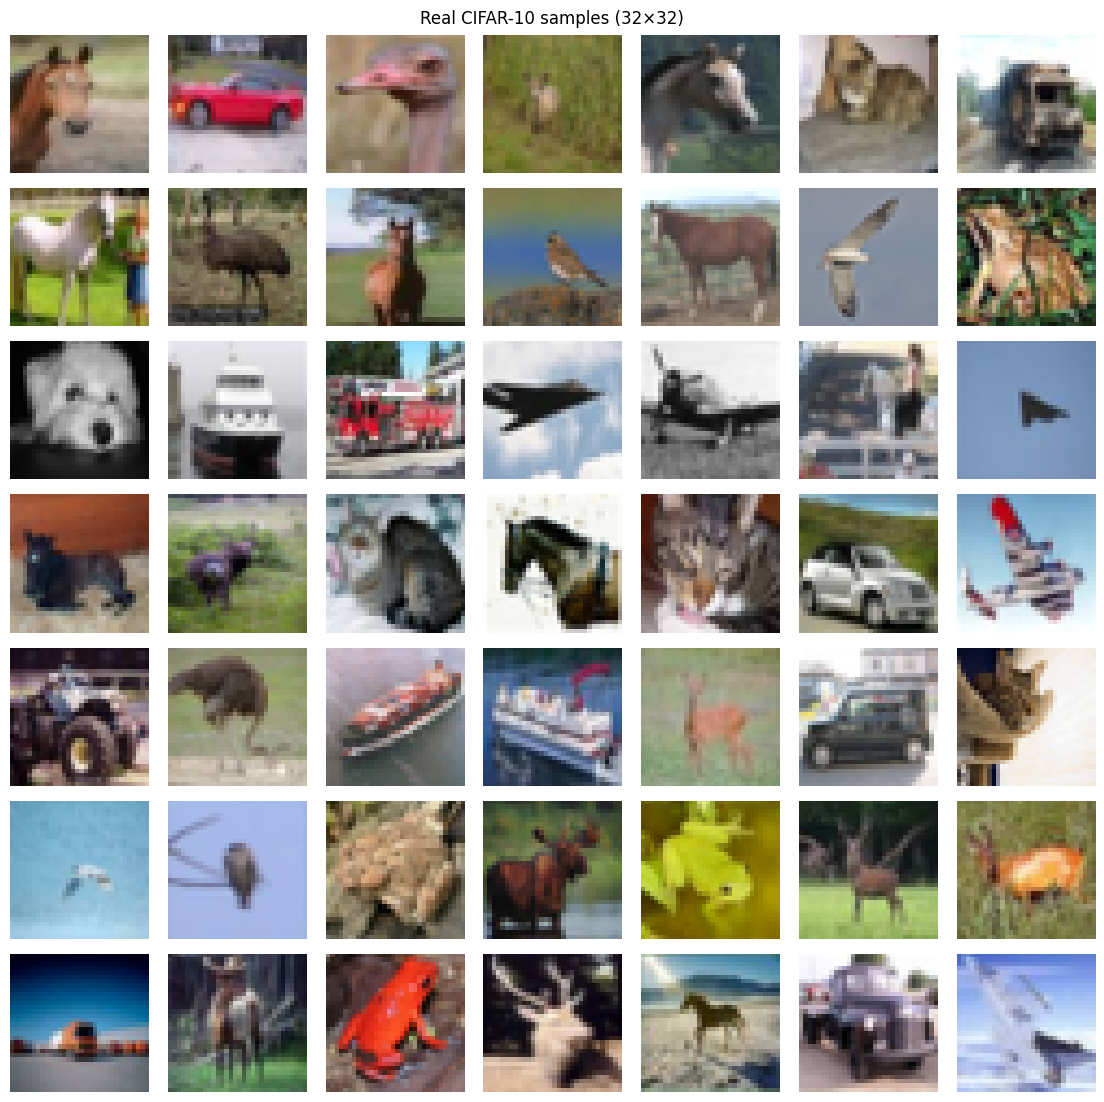

In [6]:
idx = np.random.choice(len(dataset), min(49, len(dataset)), replace=False)
plot_grid(dataset[idx], title='Real CIFAR-10 samples (32×32)')


## 3. Define the Discriminator
The discriminator is a smaller CNN to speed up training at 32×32 resolution. Strided convolutions downsample the image, LeakyReLU activations help gradient flow, and a sigmoid output predicts real vs fake.


In [7]:
def define_discriminator(in_shape=(IMG_SIZE, IMG_SIZE, 3)):
    model = keras.Sequential(name='discriminator')
    model.add(layers.Input(shape=in_shape))
    model.add(layers.Conv2D(32, (4, 4), strides=(2, 2), padding='same'))  # 32 -> 16
    model.add(layers.LeakyReLU(0.2))
    model.add(layers.Conv2D(64, (4, 4), strides=(2, 2), padding='same'))  # 16 -> 8
    model.add(layers.LeakyReLU(0.2))
    model.add(layers.Conv2D(128, (4, 4), strides=(2, 2), padding='same')) # 8 -> 4
    model.add(layers.LeakyReLU(0.2))
    model.add(layers.Flatten())
    model.add(layers.Dropout(0.3))
    model.add(layers.Dense(1, activation='sigmoid'))
    return model

d_model = define_discriminator()
d_model.summary()


Model: "discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 16, 16, 32)     │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 8, 8, 64)       │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 128)      │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         2,049 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 167,649 (654.88 KB)

 Trainable params: 167,649 (654.88 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Define the Generator
The smaller Generator maps a 100-dimensional noise vector to a 32×32×3 RGB image. Three upsampling stages reduce compute time; `tanh` produces pixels in `[-1, 1]`.


In [8]:
LATENT_DIM = 100

def define_generator(latent_dim=LATENT_DIM):
    model = keras.Sequential(name='generator')
    model.add(layers.Input(shape=(latent_dim,)))
    model.add(layers.Dense(128 * 4 * 4))
    model.add(layers.LeakyReLU(0.2))
    model.add(layers.Reshape((4, 4, 128)))
    model.add(layers.Conv2DTranspose(128, (4, 4), strides=(2, 2), padding='same')) # 4 -> 8
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU(0.2))
    model.add(layers.Conv2DTranspose(64, (4, 4), strides=(2, 2), padding='same'))  # 8 -> 16
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU(0.2))
    model.add(layers.Conv2DTranspose(32, (4, 4), strides=(2, 2), padding='same'))  # 16 -> 32
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU(0.2))
    model.add(layers.Conv2D(3, (3, 3), activation='tanh', padding='same'))
    return model

g_model = define_generator()
g_model.summary()


Model: "generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 2048)           │       206,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 8, 8, 128)      │       262,272 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 16, 16, 64)     │       131,136 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 32, 32, 32)     │        32,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 3)      │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 634,819 (2.42 MB)

 Trainable params: 634,371 (2.42 MB)

 Non-trainable params: 448 (1.75 KB)

Before training, the generator produces only random noise – this is the baseline we will compare against:

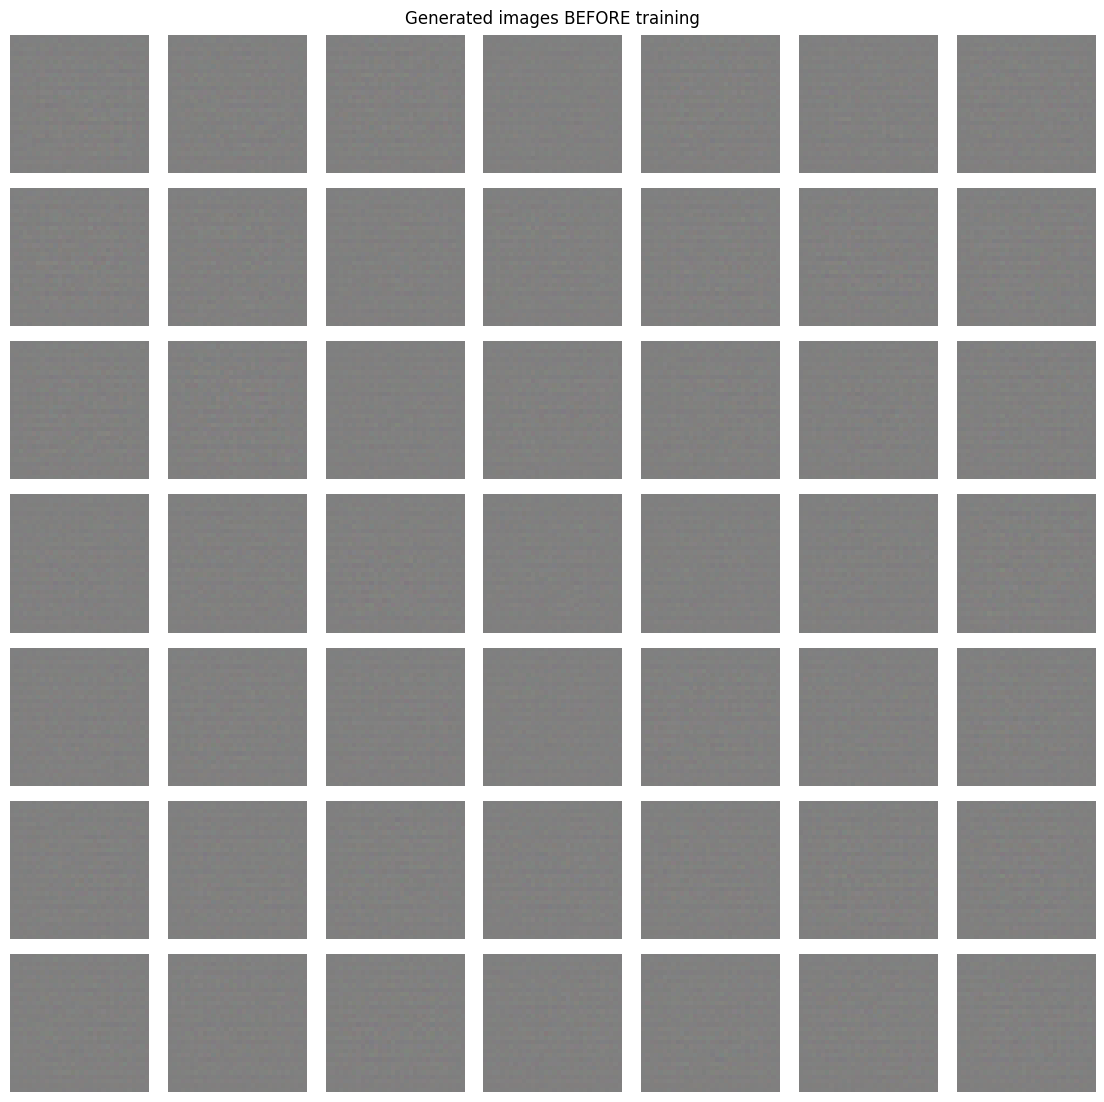

In [9]:
def generate_latent_points(latent_dim, n_samples):
    return np.random.randn(n_samples, latent_dim).astype('float32')

noise_imgs = g_model.predict(generate_latent_points(LATENT_DIM, 49), verbose=0)
plot_grid(noise_imgs, title='Generated images BEFORE training')

## 5. Adversarial Training Setup
Training alternates between two steps for every batch:

1. **Discriminator step** – train on real images (label 1) and generated images (label 0). One-sided label smoothing uses real label = 0.9.
2. **Generator step** – train the generator so generated images are classified as real.

The training uses `tf.GradientTape` to update each network separately. Random horizontal flips are applied to real images as data augmentation. Vertical flips are avoided because upside-down object images may be less natural for CIFAR-10.


In [10]:
BATCH_SIZE = 32          # Smaller batches reduce compute per update
HALF_BATCH = BATCH_SIZE // 2
EPOCHS     = 2           # Fast demonstration run; increase for better quality
LR, BETA1  = 0.0002, 0.5

bce   = keras.losses.BinaryCrossentropy()
d_opt = keras.optimizers.Adam(LR, beta_1=BETA1)
g_opt = keras.optimizers.Adam(LR, beta_1=BETA1)

def generate_real_samples(dataset, n_samples):
    ix = np.random.randint(0, dataset.shape[0], n_samples)
    X = dataset[ix].copy()
    flip_h = np.random.rand(n_samples) < 0.5  # horizontal augmentation
    X[flip_h] = X[flip_h][:, :, ::-1, :]
    y = np.ones((n_samples, 1), dtype='float32') * 0.9  # one-sided label smoothing
    return X, y

def generate_fake_samples(g_model, latent_dim, n_samples):
    x_input = generate_latent_points(latent_dim, n_samples)
    X = g_model.predict(x_input, verbose=0)
    y = np.zeros((n_samples, 1), dtype='float32')
    return X, y

@tf.function
def train_d_step(real_x, real_y, fake_x, fake_y):
    with tf.GradientTape() as tape:
        p_real = d_model(real_x, training=True)
        p_fake = d_model(fake_x, training=True)
        d_loss_real = bce(real_y, p_real)
        d_loss_fake = bce(fake_y, p_fake)
        d_loss = 0.5 * (d_loss_real + d_loss_fake)
    grads = tape.gradient(d_loss, d_model.trainable_variables)
    d_opt.apply_gradients(zip(grads, d_model.trainable_variables))
    acc_real = tf.reduce_mean(tf.cast(p_real > 0.5, tf.float32))
    acc_fake = tf.reduce_mean(tf.cast(p_fake < 0.5, tf.float32))
    return d_loss, acc_real, acc_fake

@tf.function
def train_g_step(z):
    with tf.GradientTape() as tape:
        fake = g_model(z, training=True)
        pred = d_model(fake, training=False)            # discriminator frozen here
        g_loss = bce(tf.ones_like(pred), pred)          # inverted labels: fake -> "real"
    grads = tape.gradient(g_loss, g_model.trainable_variables)   # only generator weights
    g_opt.apply_gradients(zip(grads, g_model.trainable_variables))
    return g_loss

## 6. Train the DCGAN (Fast Run)
This quick configuration uses 1,000 images and 2 epochs. Generated samples are saved after the first epoch and at the end. Training longer on a GPU generally improves quality.


Epoch   1/2 | D loss 0.514 | G loss 0.743 | D acc real 98% fake 68% | 14s


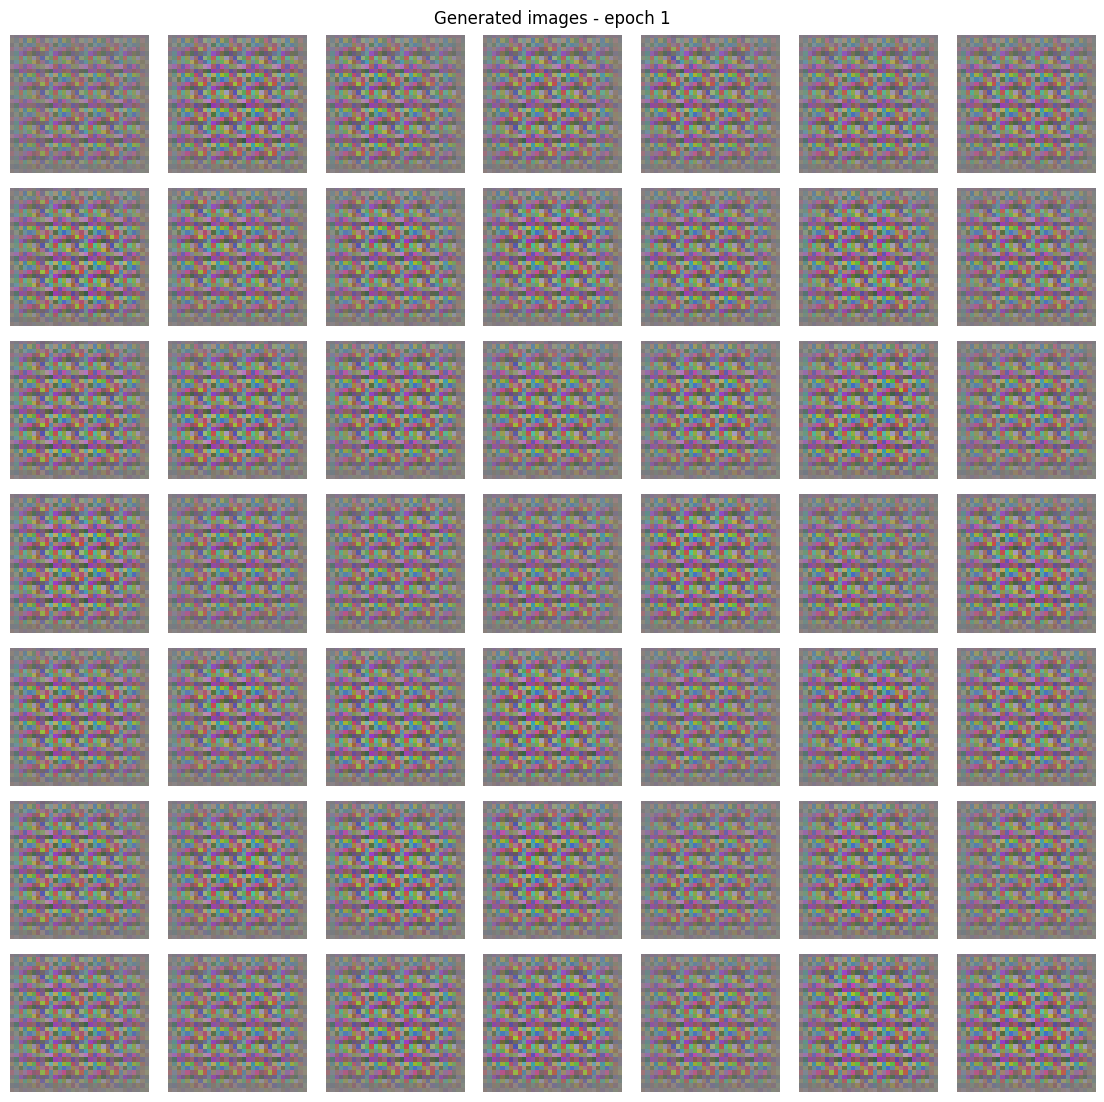

Epoch   2/2 | D loss 0.289 | G loss 3.882 | D acc real 92% fake 100% | 21s


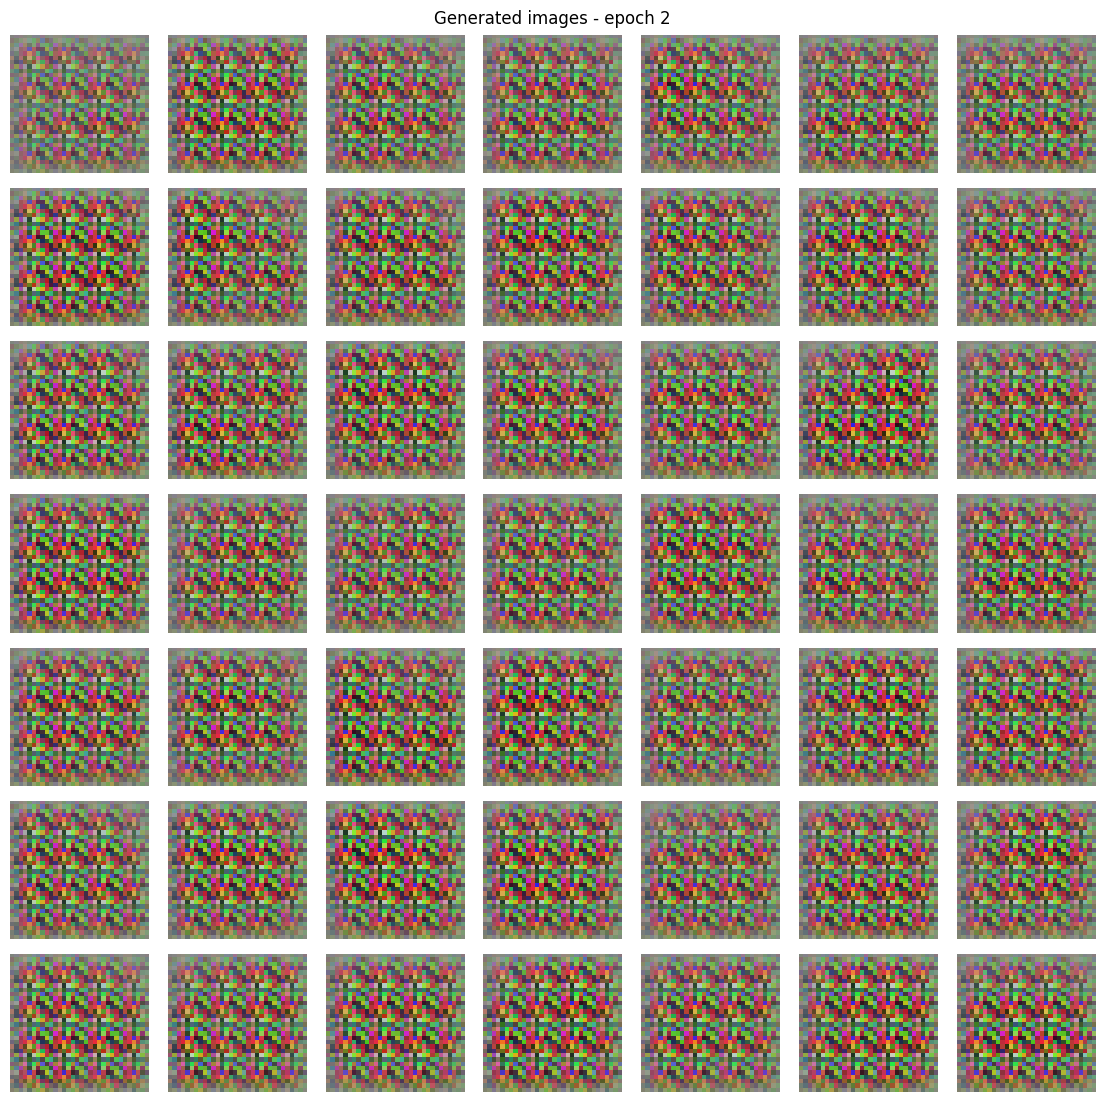

Total training time: 22.0 seconds


In [11]:
os.makedirs('outputs', exist_ok=True)
FIXED_NOISE = generate_latent_points(LATENT_DIM, 49)    # same noise every time -> comparable progress
history = {'d_loss': [], 'g_loss': [], 'acc_real': [], 'acc_fake': []}

def summarize_performance(epoch, g_model):
    imgs = g_model.predict(FIXED_NOISE, verbose=0)
    plot_grid(imgs, title=f'Generated images - epoch {epoch+1}',
              save=f'outputs/generated_e{epoch+1:03d}.png')
    g_model.save(f'outputs/generator_e{epoch+1:03d}.keras')

def train(g_model, d_model, dataset, latent_dim, n_epochs=EPOCHS, n_batch=BATCH_SIZE):
    bat_per_epo = max(1, dataset.shape[0] // HALF_BATCH)
    start = time.time()
    for i in range(n_epochs):
        dl, gl, ar, af = [], [], [], []
        for j in range(bat_per_epo):
            X_real, y_real = generate_real_samples(dataset, HALF_BATCH)
            X_fake, y_fake = generate_fake_samples(g_model, latent_dim, HALF_BATCH)
            d_loss, a_r, a_f = train_d_step(X_real, y_real, X_fake, y_fake)
            g_loss = train_g_step(generate_latent_points(latent_dim, n_batch))
            dl.append(float(d_loss)); gl.append(float(g_loss))
            ar.append(float(a_r));    af.append(float(a_f))
        history['d_loss'].append(np.mean(dl));  history['g_loss'].append(np.mean(gl))
        history['acc_real'].append(np.mean(ar)); history['acc_fake'].append(np.mean(af))
        print(f'Epoch {i+1:3d}/{n_epochs} | D loss {history["d_loss"][-1]:.3f} | '
              f'G loss {history["g_loss"][-1]:.3f} | D acc real {history["acc_real"][-1]*100:.0f}% '
              f'fake {history["acc_fake"][-1]*100:.0f}% | {time.time()-start:.0f}s')
        if (i + 1) % 1 == 0:
            summarize_performance(i, g_model)

training_start = time.time()
train(g_model, d_model, dataset, LATENT_DIM)
training_seconds = time.time() - training_start
print(f'Total training time: {training_seconds:.1f} seconds')
g_model.save('outputs/generator_final.keras')
d_model.save('outputs/discriminator_final.keras')

## 7. Evaluation

### 7.1 Generator and Discriminator Loss Curves
How to read them:
* GAN losses compete and do not need to decrease smoothly.
* A discriminator loss near 0.69 can indicate it is having difficulty distinguishing real from fake.
* If the discriminator dominates, generator loss may rise and image quality may remain poor. Check both curves and generated samples.

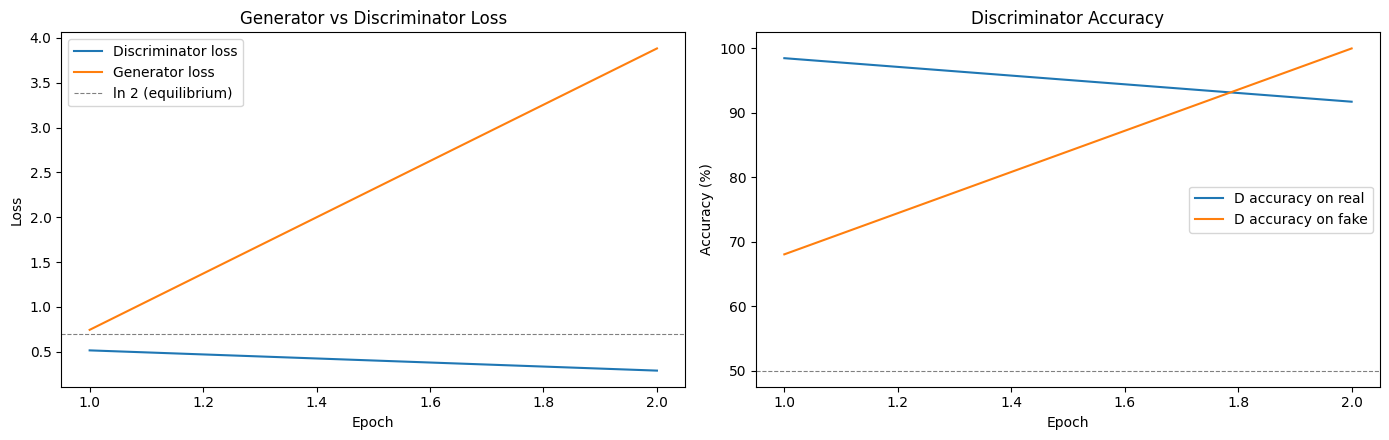

In [12]:
epochs_range = np.arange(1, len(history['d_loss']) + 1)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

ax[0].plot(epochs_range, history['d_loss'], label='Discriminator loss')
ax[0].plot(epochs_range, history['g_loss'], label='Generator loss')
ax[0].axhline(np.log(2), color='gray', ls='--', lw=0.8, label='ln 2 (equilibrium)')
ax[0].set_title('Generator vs Discriminator Loss'); ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Loss'); ax[0].legend()

ax[1].plot(epochs_range, np.array(history['acc_real']) * 100, label='D accuracy on real')
ax[1].plot(epochs_range, np.array(history['acc_fake']) * 100, label='D accuracy on fake')
ax[1].axhline(50, color='gray', ls='--', lw=0.8)
ax[1].set_title('Discriminator Accuracy'); ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Accuracy (%)'); ax[1].legend()

plt.tight_layout(); plt.savefig('outputs/loss_curves.png', dpi=130); plt.show()

### 7.2 Generate Synthetic Images with the Trained Generator

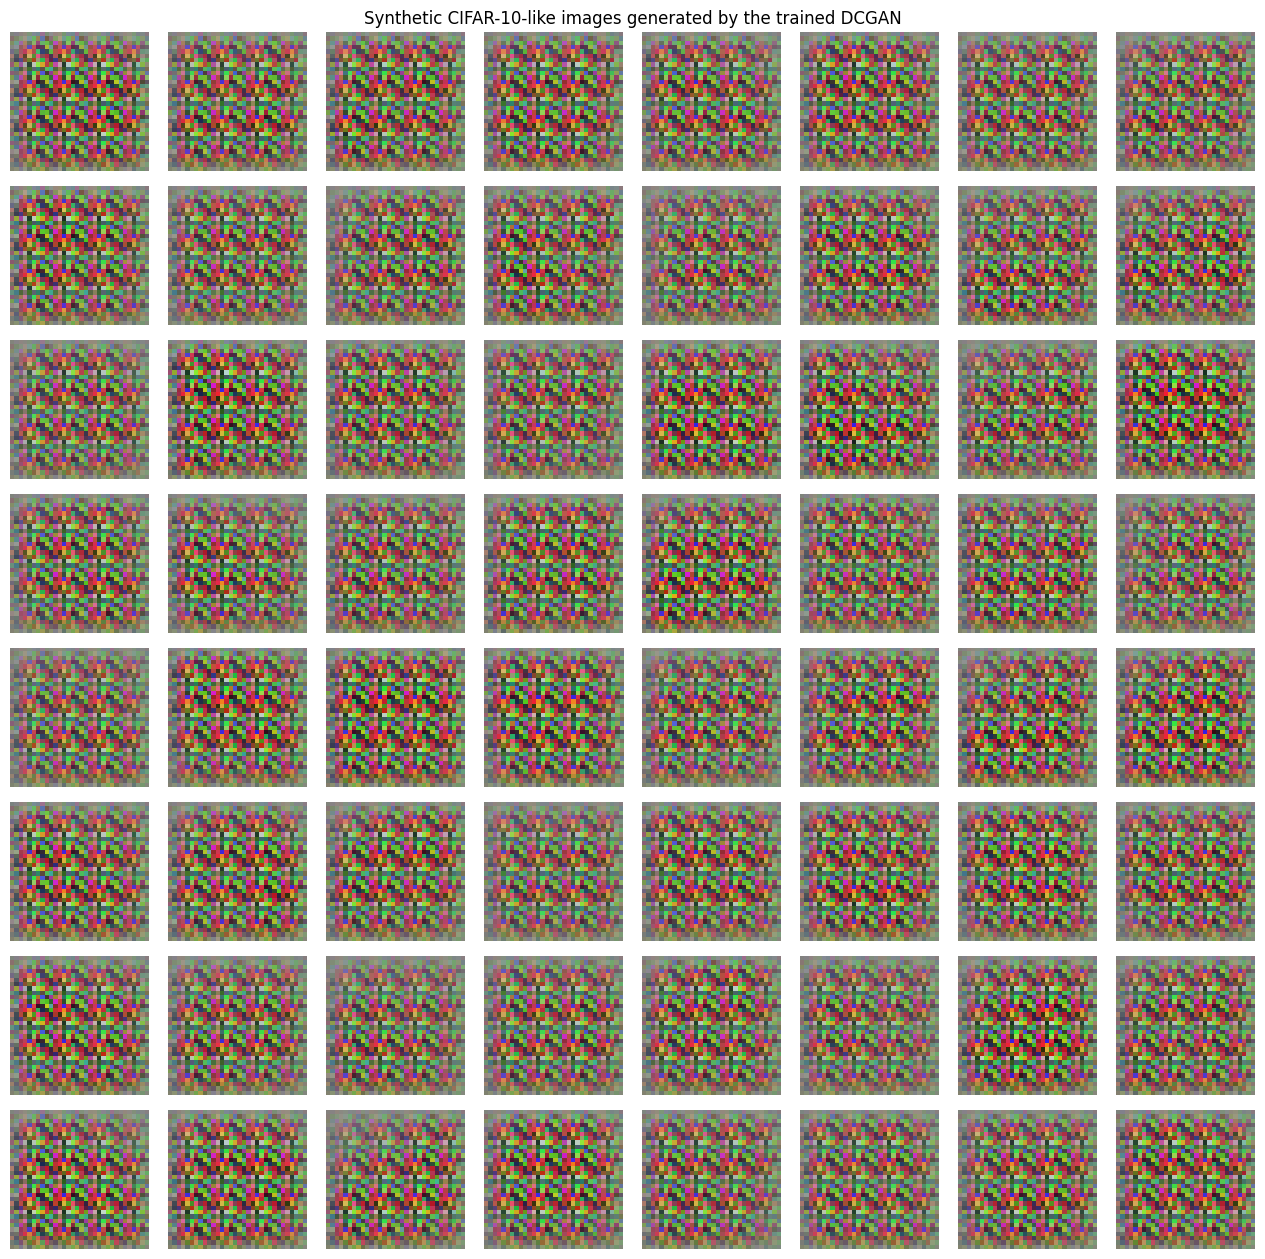

In [13]:
n = 8
z = generate_latent_points(LATENT_DIM, n * n)
fake_imgs = g_model.predict(z, verbose=0)
plot_grid(fake_imgs, n=n, title='Synthetic CIFAR-10-like images generated by the trained DCGAN',
          save='outputs/final_generated.png')

### 7.3 Real vs Generated Images (side by side)

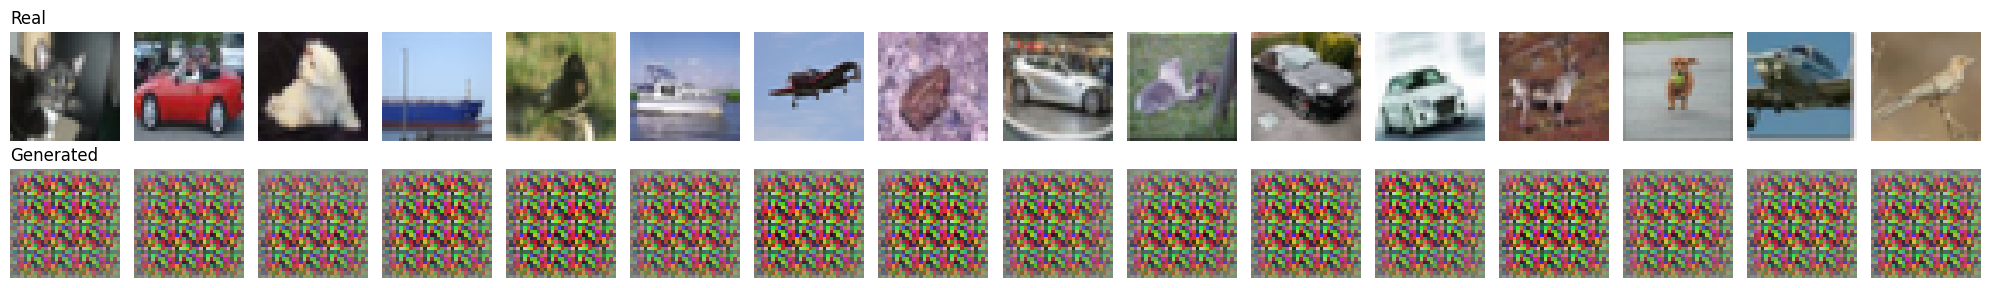

In [14]:
real_show = dataset[np.random.choice(len(dataset), 16, replace=False)]
fake_show = g_model.predict(generate_latent_points(LATENT_DIM, 16), verbose=0)
fig, ax = plt.subplots(2, 16, figsize=(20, 3))
for i in range(16):
    ax[0, i].imshow((real_show[i] + 1) / 2); ax[0, i].axis('off')
    ax[1, i].imshow(np.clip((fake_show[i] + 1) / 2, 0, 1)); ax[1, i].axis('off')
ax[0, 0].set_title('Real', loc='left'); ax[1, 0].set_title('Generated', loc='left')
plt.tight_layout(); plt.savefig('outputs/real_vs_fake.png', dpi=130); plt.show()

### 7.4 Latent-Space Interpolation
Smoothly moving between two latent vectors creates a sequence of generated images, allowing visual inspection of changes in the generator's output.

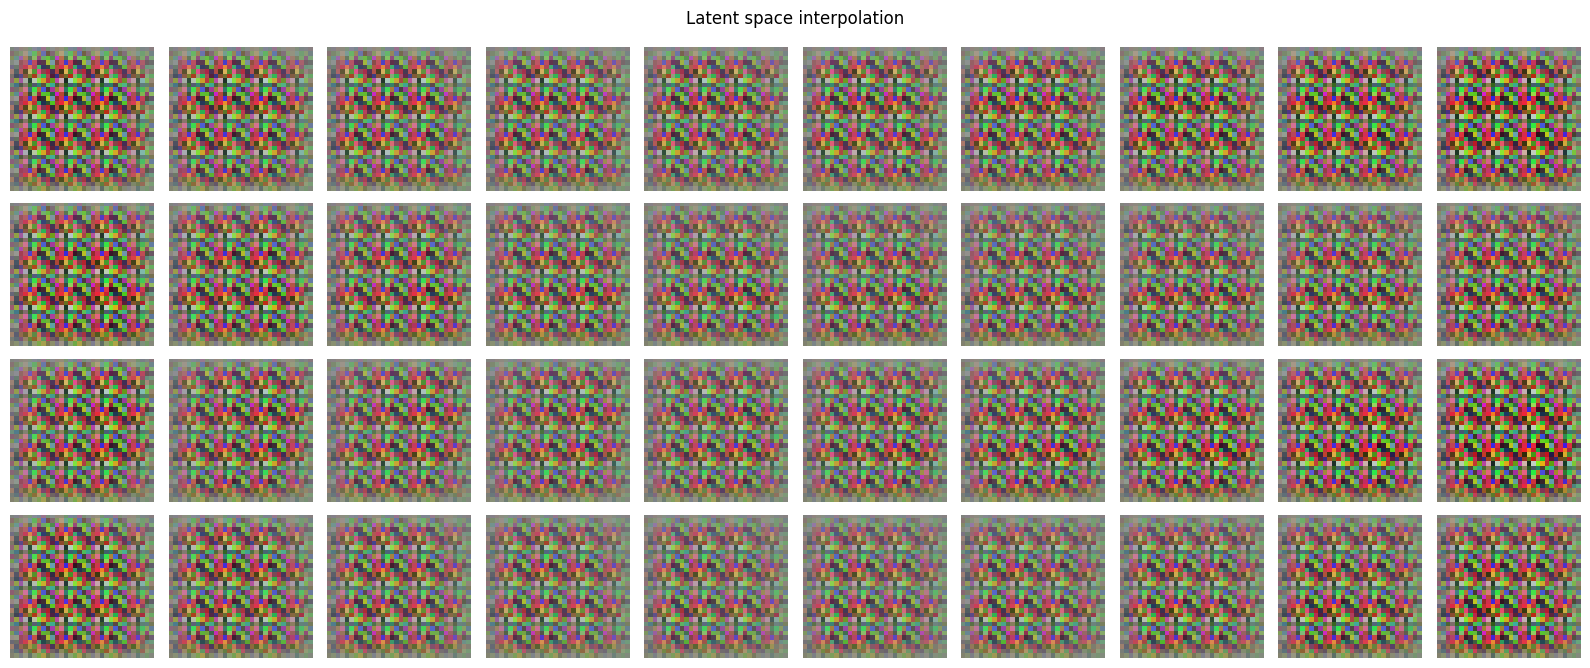

In [15]:
def interpolate(z1, z2, steps=10):
    ratios = np.linspace(0, 1, steps)
    return np.array([(1 - r) * z1 + r * z2 for r in ratios])

rows = 4
fig, ax = plt.subplots(rows, 10, figsize=(16, rows * 1.7))
for r in range(rows):
    zs = interpolate(np.random.randn(LATENT_DIM), np.random.randn(LATENT_DIM))
    imgs = (g_model.predict(zs.astype('float32'), verbose=0) + 1) / 2
    for c in range(10):
        ax[r, c].imshow(np.clip(imgs[c], 0, 1)); ax[r, c].axis('off')
plt.suptitle('Latent space interpolation'); plt.tight_layout(); plt.show()

### 7.5 Optional Quantitative Metric – Fréchet Inception Distance (FID)
FID requires downloading pretrained InceptionV3 weights and can take much longer than the training demo. It is disabled by default to keep this notebook fast. Set `RUN_FID = True` if you have extra time and a GPU.


In [18]:
from scipy import linalg

def calculate_fid(real, fake, batch=100):
    inc = keras.applications.InceptionV3(include_top=False, pooling='avg',
                                         input_shape=(299, 299, 3))
    def feats(x):
        x = (x + 1) / 2 * 255.0
        out = []
        for i in range(0, len(x), batch):
            b = tf.image.resize(x[i:i + batch], (299, 299)).numpy()
            b = keras.applications.inception_v3.preprocess_input(b)
            out.append(inc.predict(b, verbose=0))
        return np.concatenate(out)
    f1, f2 = feats(real), feats(fake)
    mu1, mu2 = f1.mean(0), f2.mean(0)
    s1, s2 = np.cov(f1, rowvar=False), np.cov(f2, rowvar=False)
    covmean = linalg.sqrtm(s1.dot(s2))
    if np.iscomplexobj(covmean): covmean = covmean.real
    return float(np.sum((mu1 - mu2) ** 2) + np.trace(s1 + s2 - 2.0 * covmean))

RUN_FID = True
if RUN_FID:
    try:
        N = min(100, len(dataset))
        real_s = dataset[np.random.choice(len(dataset), N, replace=False)]
        fake_s = g_model.predict(generate_latent_points(LATENT_DIM, N), verbose=0)
        print('FID (trained generator vs real): %.2f' % calculate_fid(real_s, fake_s))
    except Exception as e:
        print('FID skipped:', e)
else:
    print('FID skipped to save time. Set RUN_FID = True to calculate it.')


87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
FID (trained generator vs real): 590.17


/tmp/ipykernel_735/1322533579.py:17: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  covmean = linalg.sqrtm(s1.dot(s2))


## 8. Results and Discussion

After running the notebook, write observations based on your actual outputs.

- **Preprocessing:** A reproducible subset of 1,000 CIFAR-10 training images was used at native 32×32 RGB resolution and normalized to [−1,1]. Set `MAX_IMAGES` higher for more data.
- **Architecture:** The Generator transforms random latent vectors into synthetic RGB images, while the Discriminator learns to distinguish real CIFAR-10 images from generated images.
- **Training:** The Generator and Discriminator were trained alternately using separate Adam optimizers. Their losses were monitored to observe the learning process and competition between the two networks.

**Loss curves**
* Describe how Generator and Discriminator losses change during the run. GAN losses do not necessarily decrease monotonically.
* Discuss whether either network appears to dominate, using the loss and accuracy curves.

**Image quality**
* Compare the real CIFAR-10 images with the generated samples.
* Note colour variation, recognizable object-like structures, blur, repeated patterns, or lack of diversity.
* Do not claim realistic results unless the generated images support that conclusion.

**Limitations / improvements**
* Five epochs is a short training run, and a 10,000-image subset may limit diversity. Outputs may be blurry or noisy.
* Improvements include using more of CIFAR-10, longer training, tuning learning rates, and evaluating FID after training.


In [20]:
import os
import time
import numpy as np

# Create output directory
OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Display project results
print("       DCGAN PROJECT - FINAL RESULTS")

print("DATASET USED: CIFAR-10")
print("Images available:", len(dataset))
print("Image tensor shape:", tuple(dataset.shape[1:]))
print("Epochs completed:", len(history['d_loss']))

print(f"Final Discriminator loss: {history['d_loss'][-1]:.4f}")
print(f"Final Generator loss:     {history['g_loss'][-1]:.4f}")

print(
    f"Final Discriminator accuracy on real images: "
    f"{history['acc_real'][-1] * 100:.1f}%"
)

print(
    f"Final Discriminator accuracy on generated images: "
    f"{history['acc_fake'][-1] * 100:.1f}%"
)

# Display training time if it was recorded
if 'training_seconds' in globals():
    print(f"Training time: {training_seconds:.1f} seconds")
else:
    print("Training time: Not recorded")

# Generate sample images
final_images = g_model.predict(
    generate_latent_points(LATENT_DIM, 16),
    verbose=0
)

print("Generated batch shape:", tuple(final_images.shape))

# Save trained models
g_model.save(os.path.join(OUTPUT_DIR, "dcgan_cifar10_generator.keras"))
d_model.save(os.path.join(OUTPUT_DIR, "dcgan_cifar10_discriminator.keras"))

print("Generator saved successfully.")
print("Discriminator saved successfully.")
print("Output directory:", OUTPUT_DIR)


       DCGAN PROJECT - FINAL RESULTS
DATASET USED: CIFAR-10
Images available: 1000
Image tensor shape: (32, 32, 3)
Epochs completed: 2
Final Discriminator loss: 0.2887
Final Generator loss:     3.8819
Final Discriminator accuracy on real images: 91.7%
Final Discriminator accuracy on generated images: 100.0%
Training time: 22.0 seconds
Generated batch shape: (16, 32, 32, 3)
Generator saved successfully.
Discriminator saved successfully.
Output directory: outputs


## 9. Conclusion
A lightweight DCGAN configuration was trained on a small subset of CIFAR-10 at native 32×32 resolution. The reduced image size, smaller networks, 1,000-image subset, two epochs, and optional FID calculation are intended to shorten runtime. Generated image quality may be limited; increase the dataset size and epochs when more training time is available.
